In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load brain metadata

In [2]:
metadata = pd.read_csv("../metadata/FeedingTimeMetadata.csv")
metadata

,Brain,Genotype,Sex,Age,Starvation_start_time,Recording,Recording_type,Recording_start_time,Stimulus,Recording_FPS,Video_FPS,Imaging_start_frame,Imaging_stop_frame,feeding_bout_1_start_frame,feeding_bout_1_stop_frame,Feeding,Emesis
0,AKG_B30,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 10:00",R1,Functional,"17/05/2026, 10:51",NHS60,NaN,15,61,31474,3256,7798,Yes,Yes
1,AKG_B31,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 11:30",R1,Functional,"17/05/2026, 12:20",NHS60,NaN,15,81,32397,3278,7841,Yes,No
2,AKG_B32,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 13:00",R1,Functional,"17/05/2026, 14:19",NHS60,NaN,15,63,31542,3334,7746,Yes,No
3,AKG_B33,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 14:30",R1,Functional,"17/05/2026, 16:51",NHS60,NaN,15,99,31602,3504,8022,Yes,No
4,AKG_B34,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 16:00",R1,Functional,"17/05/2026, 18:52",NHS60,NaN,15,0,32396,3283,7787,Yes,No
5,AKG_B35,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 17:30",R1,Functional,"17/05/2026, 22:46",Sucrose,NaN,15,199,31667,3355,7860,Yes,No
6,AKG_B36,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 19:00",R1,Functional,"18/05/2026, 00:18",Sucrose,NaN,15,66,31553,3204,7788,Yes,No
7,AKG_B37,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 20:30",R1,Functional,"18/05/2026, 01:57",Sucrose,NaN,15,66,32397,3305,7904,Yes,No
8,AKG_B38,TH(D4)>GCaMP6m,Female,"20,21","16/05/2026, 22:00",R1,Functional,"18/05/2026, 03:28",Sucrose,NaN,15,0,32397,3505,8141,Yes,No
9,AKG_B40,TH(D4)>GCaMP6m,Female,"24,25","17/05/2026, 18:05",R1,Functional,"18/05/2026, 18:29",NHS60,NaN,30,214,63212,6997,16097,Yes,Yes


### Load mask metadata

In [3]:
mask_metadata = pd.read_csv("../metadata/MaskDescriptions.csv")
mask_metadata

,Brain,Recording,Stimulus,Mask,Plane,Region,Side
0,AKG_B30,R1,NHS60,5,1,gamma1pedc,Right
1,AKG_B30,R1,NHS60,2,1,gamma1pedc,Left
2,AKG_B31,R1,NHS60,2,0,gamma1pedc,Left
3,AKG_B31,R1,NHS60,3,1,gamma1pedc,Right
4,AKG_B32,R1,NHS60,2,0,gamma1pedc,Left
5,AKG_B32,R1,NHS60,3,1,gamma1pedc,Left
6,AKG_B32,R1,NHS60,6,1,gamma1pedc,Right
7,AKG_B33,R1,NHS60,6,0,gamma1pedc,Right
8,AKG_B33,R1,NHS60,2,0,gamma1pedc,Left
9,AKG_B34,R1,NHS60,2,0,gamma1pedc,Left


In [4]:
# Add imaging FPS column in the mask metadata to be filled in the next code cell
mask_metadata["Imaging_FPS"] = np.ones(mask_metadata.shape[0])*np.nan
mask_metadata["Video_FPS"] = np.ones(mask_metadata.shape[0])*np.nan
mask_metadata["Feeding_start_time (s)"] = np.ones(mask_metadata.shape[0])*np.nan
mask_metadata["Feeding_stop_time (s)"] = np.ones(mask_metadata.shape[0])*np.nan
mask_metadata["Feeding_duration (s)"] = np.ones(mask_metadata.shape[0])*np.nan
mask_metadata

,Brain,Recording,Stimulus,Mask,Plane,Region,Side,Imaging_FPS,Video_FPS,Feeding_start_time (s),Feeding_stop_time (s),Feeding_duration (s)
0,AKG_B30,R1,NHS60,5,1,gamma1pedc,Right,NaN,NaN,NaN,NaN,NaN
1,AKG_B30,R1,NHS60,2,1,gamma1pedc,Left,NaN,NaN,NaN,NaN,NaN
2,AKG_B31,R1,NHS60,2,0,gamma1pedc,Left,NaN,NaN,NaN,NaN,NaN
3,AKG_B31,R1,NHS60,3,1,gamma1pedc,Right,NaN,NaN,NaN,NaN,NaN
4,AKG_B32,R1,NHS60,2,0,gamma1pedc,Left,NaN,NaN,NaN,NaN,NaN
5,AKG_B32,R1,NHS60,3,1,gamma1pedc,Left,NaN,NaN,NaN,NaN,NaN
6,AKG_B32,R1,NHS60,6,1,gamma1pedc,Right,NaN,NaN,NaN,NaN,NaN
7,AKG_B33,R1,NHS60,6,0,gamma1pedc,Right,NaN,NaN,NaN,NaN,NaN
8,AKG_B33,R1,NHS60,2,0,gamma1pedc,Left,NaN,NaN,NaN,NaN,NaN
9,AKG_B34,R1,NHS60,2,0,gamma1pedc,Left,NaN,NaN,NaN,NaN,NaN


### Generate data summary dataframes

In [5]:
# Define global dataframes to populate in the loop over mask metadata rows
df_relative_timestamps = pd.DataFrame()
df_shifted_timestamps = pd.DataFrame()
df_F_traces = pd.DataFrame()
df_dFF_traces = pd.DataFrame()

# Loop over mask metadata rows to populate the global dataframes
for i in range(mask_metadata.shape[0]):

    # Get relevant variables for selected row of the mask metadata
    brain_id = mask_metadata.loc[i,"Brain"]
    recording_id = mask_metadata.loc[i,"Recording"]
    stimulus = mask_metadata.loc[i,"Stimulus"]
    mask_id = mask_metadata.loc[i,"Mask"]
    plane_id = mask_metadata.loc[i,"Plane"]
    region = mask_metadata.loc[i,"Region"]
    side = mask_metadata.loc[i,"Side"]

    # Format column name for using in the final summary dataframes
    col_name = f"{brain_id}_{recording_id}_mask{mask_id}_plane{plane_id}_{region}_{stimulus}"
    
    # Get feeding start and stop times from brain metadata
    brain_metadata = metadata[(metadata["Brain"] == brain_id) & (metadata["Recording"] == recording_id)]
    
    video_FPS = np.squeeze(brain_metadata["Video_FPS"])
    mask_metadata.loc[i,"Video_FPS"] = video_FPS
    
    feeding_1_start_time = np.squeeze(brain_metadata["feeding_bout_1_start_frame"])/video_FPS # seconds
    mask_metadata.loc[i,"Feeding_start_time (s)"] = feeding_1_start_time
    
    feeding_1_stop_time = np.squeeze(brain_metadata["feeding_bout_1_stop_frame"])/video_FPS # seconds
    mask_metadata.loc[i,"Feeding_stop_time (s)"] = feeding_1_stop_time
    
    feeding_duration = feeding_1_stop_time - feeding_1_start_time
    mask_metadata.loc[i,"Feeding_duration (s)"] = feeding_duration
    
    # Load the raw fluorescence data for the selected row of mask metadata
    df_data = pd.read_csv(f"../data/{brain_id}/csv_files/{recording_id}_plane{plane_id}_data.csv")
    
    # Calculate imaging FPS from the timestamps column
    imaging_FPS = 1000/df_data["relative_timestamps(ms)"].diff().mean()
    mask_metadata.loc[i,"Imaging_FPS"] = imaging_FPS

    # Shift the timestamps such that feeding starts at time zero
    shifted_timestamps = df_data["relative_timestamps(ms)"] - feeding_1_start_time*1000
    
    # Save relative timestamps and shifted timestamps for each row of mask metadata to respective global dataframes
    df_relative_timestamps[col_name] = pd.Series(df_data["relative_timestamps(ms)"].values)
    df_shifted_timestamps[col_name] = pd.Series(shifted_timestamps.values)

    # Get pre-feeding, during-feeding, and post-feeding phase indices from the relative timestamps and feeding start and stop times for a given row of mask metadata
    pre_feeding_idx = (df_data[df_data["relative_timestamps(ms)"] < feeding_1_start_time*1000]).index
    during_feeding_idx = (df_data[(df_data["relative_timestamps(ms)"] >= feeding_1_start_time*1000) & (df_data["relative_timestamps(ms)"] < feeding_1_stop_time*1000)]).index
    post_feeding_window_idx = (df_data[df_data["relative_timestamps(ms)"] >= feeding_1_stop_time*1000]).index
    
    # Calculate dFF trace using indices calculated above 
    col = f"F_trace_Mask_{mask_id}_plane{plane_id}"
    dFF_trace_col = df_data[col]/(df_data.loc[pre_feeding_idx,col].mean(axis=0,skipna=True)) - 1

    # Save dFF traces for each row of mask metadata to a global dataframe
    df_dFF_traces[col_name] = pd.Series(dFF_trace_col.values)
    
    # Save raw fluorescence intensities for each row of mask metadata to a global dataframe
    df_F_traces[col_name] = pd.Series(df_data[col].values)

mask_metadata.to_csv("../metadata/Recording_metadata.csv",index = None)
mask_metadata

,Brain,Recording,Stimulus,Mask,Plane,Region,Side,Imaging_FPS,Video_FPS,Feeding_start_time (s),Feeding_stop_time (s),Feeding_duration (s)
0,AKG_B30,R1,NHS60,5,1,gamma1pedc,Right,1.254170,15.0,217.066667,519.866667,302.800000
1,AKG_B30,R1,NHS60,2,1,gamma1pedc,Left,1.254170,15.0,217.066667,519.866667,302.800000
2,AKG_B31,R1,NHS60,2,0,gamma1pedc,Left,1.377122,15.0,218.533333,522.733333,304.200000
3,AKG_B31,R1,NHS60,3,1,gamma1pedc,Right,1.377088,15.0,218.533333,522.733333,304.200000
4,AKG_B32,R1,NHS60,2,0,gamma1pedc,Left,1.251235,15.0,222.266667,516.400000,294.133333
5,AKG_B32,R1,NHS60,3,1,gamma1pedc,Left,1.251212,15.0,222.266667,516.400000,294.133333
6,AKG_B32,R1,NHS60,6,1,gamma1pedc,Right,1.251212,15.0,222.266667,516.400000,294.133333
7,AKG_B33,R1,NHS60,6,0,gamma1pedc,Right,1.281426,15.0,233.600000,534.800000,301.200000
8,AKG_B33,R1,NHS60,2,0,gamma1pedc,Left,1.281426,15.0,233.600000,534.800000,301.200000
9,AKG_B34,R1,NHS60,2,0,gamma1pedc,Left,1.316616,15.0,218.866667,519.133333,300.266667


### Timestamp alignment of data obtained from all the rows of mask metadata

In [6]:
# Calculate target FPS from the mask_metadata dataframe which will be used to get common timestamps for all the data
target_fps = np.mean(mask_metadata["Imaging_FPS"].unique())
target_fps

np.float64(1.2942504227717226)

In [7]:
def align_to_stimulus(df_timestamps, df_intensities, target_hz):
    """
    Aligns stimulus-centered time series (where t=0 is the stimulus onset)
    onto a common time vector while keeping zero-crossings perfectly aligned.
    """
    dt = 1000 / target_hz #ms
    
    # 1. Find the absolute maximum limits of your recordings across all ROIs
    # Using np.nanmin/nanmax safely ignores the NaN padding in your dataframes
    global_min = np.nanmin(df_timestamps.values)
    global_max = np.nanmax(df_timestamps.values)
    
    # 2. Build a Zero-Anchored Time Vector
    # Pre-stimulus (negative times): Step backward from 0, remove the 0, and reverse order
    time_pre = np.arange(global_min, 0, dt)
    
    # Post-stimulus (positive times): Step forward from 0
    time_post = np.arange(0, global_max + dt, dt)
    
    # Combine to guarantee 0.0 is an exact, stationary knot in the array
    common_time = np.concatenate((time_pre, time_post))
    
    aligned_data = {}
    
    # 3. Interpolate each ROI separately
    for col in df_timestamps.columns:
        valid_mask = df_timestamps[col].notna() & df_intensities[col].notna()
        
        original_times = df_timestamps.loc[valid_mask, col].values
        original_intensities = df_intensities.loc[valid_mask, col].values
        
        if len(original_times) > 0:
            # left=np.nan and right=np.nan ensure that we do not invent data 
            # for times before an ROI started recording or after it finished.
            interpolated_signal = np.interp(
                common_time, 
                original_times, 
                original_intensities,
                left=np.nan, 
                right=np.nan
            )
            aligned_data[col] = interpolated_signal
            
    # 4. Construct final DataFrame
    df_aligned = pd.DataFrame(aligned_data, index=common_time)
    df_aligned.index.name = 'Time_from_Stimulus (ms)'
    
    return df_aligned

In [8]:
# Get time aligned dFF data from raw data using function defined above
df_dFF_aligned = align_to_stimulus(df_timestamps= df_shifted_timestamps, df_intensities= df_dFF_traces, target_hz=target_fps)
df_dFF_aligned

,AKG_B30_R1_mask5_plane1_gamma1pedc_NHS60,AKG_B30_R1_mask2_plane1_gamma1pedc_NHS60,AKG_B31_R1_mask2_plane0_gamma1pedc_NHS60,AKG_B31_R1_mask3_plane1_gamma1pedc_NHS60,AKG_B32_R1_mask2_plane0_gamma1pedc_NHS60,AKG_B32_R1_mask3_plane1_gamma1pedc_NHS60,AKG_B32_R1_mask6_plane1_gamma1pedc_NHS60,AKG_B33_R1_mask6_plane0_gamma1pedc_NHS60,AKG_B33_R1_mask2_plane0_gamma1pedc_NHS60,AKG_B34_R1_mask2_plane0_gamma1pedc_NHS60,...,AKG_B35_R1_mask4_plane0_gamma1pedc_Sucrose,AKG_B35_R1_mask5_plane0_gamma1pedc_Sucrose,AKG_B36_R1_mask2_plane0_gamma1pedc_Sucrose,AKG_B36_R1_mask5_plane0_gamma1pedc_Sucrose,AKG_B37_R1_mask3_plane0_gamma1pedc_Sucrose,AKG_B37_R1_mask4_plane0_gamma1pedc_Sucrose,AKG_B38_R1_mask2_plane0_gamma1pedc_Sucrose,AKG_B38_R1_mask4_plane0_gamma1pedc_Sucrose,AKG_B42_R1_mask2_plane0_gamma1pedc_Sucrose,AKG_B42_R1_mask4_plane0_gamma1pedc_Sucrose
Time_from_Stimulus (ms),,,,,,,,,,,,,,,,,,,,,
-2.672667e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.203336,-0.175065
-2.664940e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.208779,-0.131114
-2.657214e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.044010,-0.041115
-2.649487e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.179864,-0.040162
-2.641761e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.025201,-0.112394
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1.879853e+06,0.949406,0.564185,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.880625e+06,1.028121,0.523891,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.881398e+06,1.184081,0.527586,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df_dFF_aligned_nan_dropped = df_dFF_aligned.dropna()
df_dFF_aligned_nan_dropped

,AKG_B30_R1_mask5_plane1_gamma1pedc_NHS60,AKG_B30_R1_mask2_plane1_gamma1pedc_NHS60,AKG_B31_R1_mask2_plane0_gamma1pedc_NHS60,AKG_B31_R1_mask3_plane1_gamma1pedc_NHS60,AKG_B32_R1_mask2_plane0_gamma1pedc_NHS60,AKG_B32_R1_mask3_plane1_gamma1pedc_NHS60,AKG_B32_R1_mask6_plane1_gamma1pedc_NHS60,AKG_B33_R1_mask6_plane0_gamma1pedc_NHS60,AKG_B33_R1_mask2_plane0_gamma1pedc_NHS60,AKG_B34_R1_mask2_plane0_gamma1pedc_NHS60,...,AKG_B35_R1_mask4_plane0_gamma1pedc_Sucrose,AKG_B35_R1_mask5_plane0_gamma1pedc_Sucrose,AKG_B36_R1_mask2_plane0_gamma1pedc_Sucrose,AKG_B36_R1_mask5_plane0_gamma1pedc_Sucrose,AKG_B37_R1_mask3_plane0_gamma1pedc_Sucrose,AKG_B37_R1_mask4_plane0_gamma1pedc_Sucrose,AKG_B38_R1_mask2_plane0_gamma1pedc_Sucrose,AKG_B38_R1_mask4_plane0_gamma1pedc_Sucrose,AKG_B42_R1_mask2_plane0_gamma1pedc_Sucrose,AKG_B42_R1_mask4_plane0_gamma1pedc_Sucrose
Time_from_Stimulus (ms),,,,,,,,,,,,,,,,,,,,,
-2.131813e+05,-0.015588,0.073091,0.076434,0.023559,-0.073936,-0.117236,-0.202572,-0.087061,-0.041635,-0.164287,...,-0.081168,-0.230022,-0.219370,-0.193934,-0.179069,-0.169296,-0.066809,-0.013204,0.037954,0.053295
-2.124087e+05,-0.192843,-0.066625,0.056142,0.080243,-0.018851,-0.115796,0.164096,-0.246028,0.174742,-0.216753,...,0.011679,-0.184484,-0.130978,-0.142893,-0.119601,-0.012223,-0.115337,-0.126684,-0.016598,-0.054955
-2.116360e+05,-0.036806,0.003317,0.035202,-0.000250,0.119901,-0.097418,0.068925,-0.269614,-0.161062,-0.139649,...,-0.336348,-0.415988,-0.116686,-0.120746,-0.099481,-0.047651,-0.148099,-0.190997,0.032051,-0.034568
-2.108634e+05,-0.071848,-0.012223,0.040652,-0.030197,-0.055412,-0.027353,0.022853,-0.212478,0.045040,-0.110268,...,-0.065408,-0.250823,-0.123999,-0.118334,0.166352,0.206585,-0.168927,-0.259822,-0.013969,-0.082995
-2.100907e+05,0.063483,0.009867,0.040722,0.027605,-0.116291,-0.109903,-0.110614,-0.127696,0.105671,-0.231954,...,-0.092716,-0.323209,-0.003494,-0.022564,-0.083059,0.082306,-0.169626,-0.177169,-0.026584,-0.128779
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1.682055e+06,0.139974,0.357039,2.188060,1.250403,1.623785,0.183762,-0.012716,0.596987,0.103542,0.370114,...,0.295230,0.922103,0.055498,0.122253,0.523081,0.351919,0.137823,-0.235651,-0.174125,-0.104361
1.682827e+06,0.013857,0.253464,2.186038,1.325929,1.493063,0.182571,0.105790,0.461553,0.112099,0.336682,...,-0.065695,0.505372,0.173443,0.371105,0.251942,0.059485,0.226073,-0.134129,-0.297607,-0.303150
1.683600e+06,0.095186,0.264066,2.128001,1.334411,1.259392,0.201591,0.124426,0.473674,0.102313,0.304743,...,0.035292,0.826924,0.268991,0.371887,0.448514,0.168868,-0.015930,-0.335399,-0.288258,-0.265620


In [10]:
region = "gamma1pedc"
mask_metadata_region = mask_metadata[mask_metadata["Region"] == region]
mask_metadata_region_NHS60 = mask_metadata_region[mask_metadata_region["Stimulus"] == "NHS60"]
mask_metadata_region_Sucrose = mask_metadata_region[mask_metadata_region["Stimulus"] == "Sucrose"]
mask_metadata_region_NHS60

,Brain,Recording,Stimulus,Mask,Plane,Region,Side,Imaging_FPS,Video_FPS,Feeding_start_time (s),Feeding_stop_time (s),Feeding_duration (s)
0,AKG_B30,R1,NHS60,5,1,gamma1pedc,Right,1.254170,15.0,217.066667,519.866667,302.800000
1,AKG_B30,R1,NHS60,2,1,gamma1pedc,Left,1.254170,15.0,217.066667,519.866667,302.800000
2,AKG_B31,R1,NHS60,2,0,gamma1pedc,Left,1.377122,15.0,218.533333,522.733333,304.200000
3,AKG_B31,R1,NHS60,3,1,gamma1pedc,Right,1.377088,15.0,218.533333,522.733333,304.200000
4,AKG_B32,R1,NHS60,2,0,gamma1pedc,Left,1.251235,15.0,222.266667,516.400000,294.133333
5,AKG_B32,R1,NHS60,3,1,gamma1pedc,Left,1.251212,15.0,222.266667,516.400000,294.133333
6,AKG_B32,R1,NHS60,6,1,gamma1pedc,Right,1.251212,15.0,222.266667,516.400000,294.133333
7,AKG_B33,R1,NHS60,6,0,gamma1pedc,Right,1.281426,15.0,233.600000,534.800000,301.200000
8,AKG_B33,R1,NHS60,2,0,gamma1pedc,Left,1.281426,15.0,233.600000,534.800000,301.200000
9,AKG_B34,R1,NHS60,2,0,gamma1pedc,Left,1.316616,15.0,218.866667,519.133333,300.266667


In [11]:
# Average all traces within a brain to represent that brain's response in the whole dataset
NHS60_brains = mask_metadata_region_NHS60["Brain"].unique()
Sucrose_brains = mask_metadata_region_Sucrose["Brain"].unique()

# For NHS60
df_dFF_aligned_NHS60 = pd.DataFrame()

for brain in NHS60_brains:

    brain_filter = [brain in col for col in df_dFF_aligned_nan_dropped.columns]

    region_filter = [region in col for col in df_dFF_aligned_nan_dropped.columns]

    col_filter = np.array(brain_filter) & np.array(region_filter)
    
    df_dFF_aligned_NHS60[brain] = df_dFF_aligned_nan_dropped.loc[:,col_filter].mean(axis=1)

# For Sucrose
df_dFF_aligned_Sucrose = pd.DataFrame()

for brain in Sucrose_brains:

    brain_filter = [brain in col for col in df_dFF_aligned_nan_dropped.columns]

    region_filter = [region in col for col in df_dFF_aligned_nan_dropped.columns]

    col_filter = np.array(brain_filter) & np.array(region_filter)
    
    df_dFF_aligned_Sucrose[brain] = df_dFF_aligned_nan_dropped.loc[:,col_filter].mean(axis=1)

df_dFF_aligned_NHS60

,AKG_B30,AKG_B31,AKG_B32,AKG_B33,AKG_B34,AKG_B40,AKG_B41
Time_from_Stimulus (ms),,,,,,,
-2.131813e+05,0.028752,0.049997,-0.131248,-0.064348,-0.122101,-0.076490,0.106766
-2.124087e+05,-0.129734,0.068192,0.009816,-0.035643,-0.198151,-0.056252,-0.159187
-2.116360e+05,-0.016744,0.017476,0.030470,-0.215338,-0.141686,-0.031844,-0.013425
-2.108634e+05,-0.042035,0.005228,-0.019971,-0.083719,-0.127171,-0.194766,-0.118313
-2.100907e+05,0.036675,0.034164,-0.112269,-0.011012,-0.224955,-0.097397,0.051631
...,...,...,...,...,...,...,...
1.682055e+06,0.248506,1.719231,0.598277,0.350264,0.216222,0.209192,0.097027
1.682827e+06,0.133660,1.755984,0.593808,0.286826,0.197356,0.109287,0.081855
1.683600e+06,0.179626,1.731206,0.528470,0.287993,0.173811,0.056728,0.039716


In [12]:
# Save stimulus wise aligned dFF traces to csv files
df_dFF_aligned_NHS60.to_csv(f"../csv_files/Brainwise_aligned_dFF_traces_of_{region}_for_NHS60.csv")
df_dFF_aligned_Sucrose.to_csv(f"../csv_files/Brainwise_aligned_dFF_traces_of_{region}_for_Sucrose.csv")

In [13]:
# Calculate mean dFF and std dFF trace for both NHS60 and Sucrose feeding experiments
NHS60_region_mean_response_trace = df_dFF_aligned_NHS60.mean(axis=1)
NHS60_region_std_response_trace = df_dFF_aligned_NHS60.std(axis=1)

Sucrose_region_mean_response_trace = df_dFF_aligned_Sucrose.mean(axis=1)
Sucrose_region_std_response_trace = df_dFF_aligned_Sucrose.std(axis=1)

In [14]:
Sucrose_region_mean_response_trace

Time_from_Stimulus (ms)
-2.131813e+05   -0.106162
-2.124087e+05   -0.089207
-2.116360e+05   -0.147851
-2.108634e+05   -0.071134
-2.100907e+05   -0.094490
                   ...   
 1.682055e+06    0.189377
 1.682827e+06    0.078684
 1.683600e+06    0.121527
 1.684373e+06    0.194350
 1.685145e+06    0.156317
Length: 2458, dtype: float64

In [15]:
df_plot = pd.DataFrame()
df_plot["mean dF/F(Sucrose)"] = Sucrose_region_mean_response_trace
df_plot["std dF/F(Sucrose)"] = Sucrose_region_std_response_trace
df_plot["mean dF/F(Sucrose+NHS)"] = NHS60_region_mean_response_trace
df_plot["std dF/F(Sucrose+NHS)"] = NHS60_region_std_response_trace
df_plot.index = df_dFF_aligned_nan_dropped.index/60000
df_plot.index.name = "Time_from_Stimulus (minutes)"
df_plot.to_csv(f"../csv_files/MeandFF_and_std_dFF_traces_of_{region}_for_Sucrose_and_NHS60.csv")
df_plot

,mean dF/F(Sucrose),std dF/F(Sucrose),mean dF/F(Sucrose+NHS),std dF/F(Sucrose+NHS)
Time_from_Stimulus (minutes),,,,
-3.553022,-0.106162,0.105575,-0.029810,0.091861
-3.540144,-0.089207,0.040911,-0.071566,0.095538
-3.527267,-0.147851,0.141824,-0.053013,0.090812
-3.514389,-0.071134,0.156092,-0.082964,0.069672
-3.501512,-0.094490,0.093379,-0.046166,0.102531
...,...,...,...,...
28.034245,0.189377,0.321031,0.491246,0.564034
28.047122,0.078684,0.228087,0.451254,0.601166
28.060000,0.121527,0.323085,0.428222,0.597627


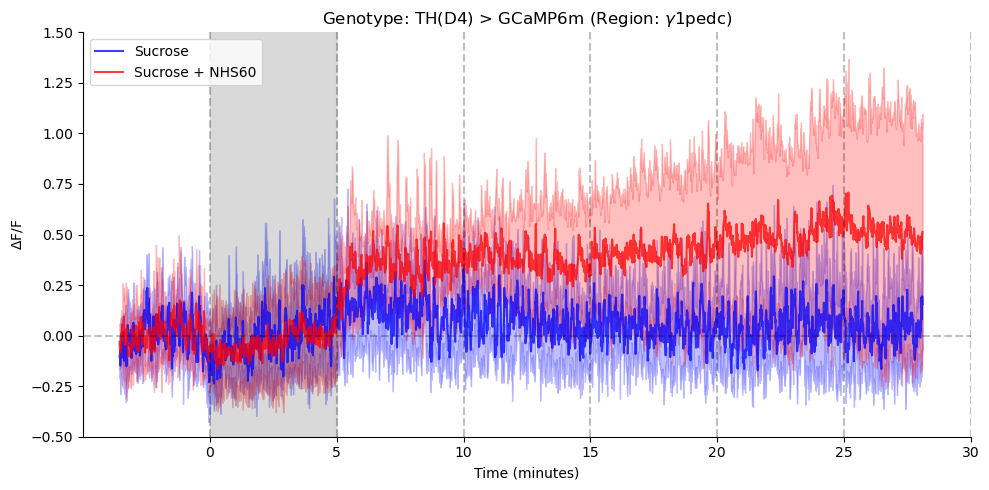

In [16]:
# Plot NHS60 and Sucrose feeding response plots
fig,ax = plt.subplots(1,1,figsize=(10,5))

time = df_dFF_aligned_nan_dropped.index/60000

ax.plot(time, Sucrose_region_mean_response_trace, color = "b", alpha = 0.75, label = "Sucrose")
ax.fill_between(time, Sucrose_region_mean_response_trace - Sucrose_region_std_response_trace,Sucrose_region_mean_response_trace + Sucrose_region_std_response_trace, color = "b", alpha = 0.25)

ax.plot(time, NHS60_region_mean_response_trace, color = "r", alpha = 0.75, label = "Sucrose + NHS60")
ax.fill_between(time, NHS60_region_mean_response_trace - NHS60_region_std_response_trace,NHS60_region_mean_response_trace + NHS60_region_std_response_trace, color = "r", alpha = 0.25)

ax.axhline(0,ls="--",color="k",alpha=0.25)
mean_feeding_duration = mask_metadata_region["Feeding_duration (s)"].mean()
ax.axvspan(0,mean_feeding_duration/60,color="k",alpha=0.15,linewidth=0)

xticks_array = [0,5,10,15,20,25,30]
ax.set_xticks(xticks_array)

for xtick in xticks_array:
    ax.axvline(xtick,color="k",ls="--",alpha=0.25)

ax.set_ylim(-0.5,1.5)
ax.set_xlim(-5,30)
ax.set_ylabel(r"$\Delta$F/F")
ax.set_xlabel("Time (minutes)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()

ax.set_title("Genotype: TH(D4) > GCaMP6m (Region: " + r"$\gamma$1pedc)")

plt.tight_layout()
plt.savefig(f"../figures/Sucrose_vs_NHS_response_comparison_TH_D4_X_GCaMP6m_{region}.svg",dpi=600,transparent=True)
